<a href="https://colab.research.google.com/github/almakhansa/SK5017-Tugas-Pendamping-UTS-20926003/blob/main/Tugas_Pendamping_UTS_SK5017_Alma_Tsabita.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**SK5017 Tugas Pendamping UTS**

##**Machine Learning Analysis Assignment: Abalone Study**

###**Part 1: Classification**
Task: Build models to predict the sex of the abalone based on its physical measurements.
* **Algorithms**: Implement two learning models: **Support Vector Machine (SVM)** and a **Random Forest**.
* **Requirements**:
  * Preprocess the data (handle categorical features, scale numerical features).
  * Train both models on the training set.
  * Evaluate performance using accuracy, precision, and recall.
  * **Comparison**: Compare the performance of SVM and RF. Which model performed better? discuss the strengths and weaknesses of each algorithm regarding this specific dataset.

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
abalone = fetch_ucirepo(id=1)

# data (as pandas dataframes)
X = abalone.data.features
y = abalone.data.targets

# metadata
print(abalone.metadata)

# variable information
print(abalone.variables)


{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

In [ ]:
import pandas as pd

# Combine features X and targets y into a single DataFrame
data = pd.concat([X, y], axis=1)

# Export to CSV
data.to_csv('abalone.csv', index=False)

# Download the file
from google.colab import files
files.download('abalone.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, classification_report, confusion_matrix)

RANDOM_STATE = 42

In [ ]:
from ucimlrepo import fetch_ucirepo
abalone = fetch_ucirepo(id=1)
df = pd.concat([abalone.data.features, abalone.data.targets], axis=1)

cols = ["Sex","Length","Diameter","Height","Whole_weight",
         "Shucked_weight","Viscera_weight","Shell_weight","Rings"]
df = pd.read_csv("abalone.csv", names=cols)

print(df.head())
print(df.info())
print("\nDistribusi kelas Sex:\n", df["Sex"].value_counts())

   Sex  Length  Diameter  Height  Whole_weight  Shucked_weight  \
0  Sex  Length  Diameter  Height  Whole_weight  Shucked_weight   
1    M   0.455     0.365   0.095         0.514          0.2245   
2    M    0.35     0.265    0.09        0.2255          0.0995   
3    F    0.53      0.42   0.135         0.677          0.2565   
4    M    0.44     0.365   0.125         0.516          0.2155   

   Viscera_weight  Shell_weight  Rings  
0  Viscera_weight  Shell_weight  Rings  
1           0.101          0.15     15  
2          0.0485          0.07      7  
3          0.1415          0.21      9  
4           0.114         0.155     10  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4178 entries, 0 to 4177
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Sex             4178 non-null   object
 1   Length          4178 non-null   object
 2   Diameter        4178 non-null   object
 3   Height          4178 non-n

###**1. Preprocess the data (handle categorical features, scale numerical features).**

In [ ]:
# Clean the data
if 'Sex' in df["Sex"].values:
    df_clean = df.drop(index=0).copy()
else:
    df_clean = df.copy()

for col in df_clean.columns:
    if col != "Sex":
        df_clean[col] = pd.to_numeric(df_clean[col])

# Target = Sex (kategorikal) diubah jadi angka dengan LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df_clean["Sex"])          # F=0, I=1, M=2
class_names = le.classes_

# Fitur = semua kolom selain Sex
X = df_clean.drop(columns=["Sex"])

# Split 80 training & 20 testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

###**2. Training Set**

In [ ]:
svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", random_state=RANDOM_STATE)),])
svm_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.1, 1],}

rf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE)),])
rf_grid = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [None, 5, 10],
    "clf__min_samples_leaf": [1, 5, 10],}

# Tuning hyperparameter pakai 5-fold CV hanya di data train
svm_search = GridSearchCV(svm_pipe, svm_grid, cv=5, scoring="accuracy", n_jobs=-1)
rf_search = GridSearchCV(rf_pipe, rf_grid, cv=5, scoring="accuracy", n_jobs=-1)

print("\nTraining SVM")
svm_search.fit(X_train, y_train)
print("Best SVM params:", svm_search.best_params_)

print("Training Random Forest")
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)


Training SVM
Best SVM params: {'clf__C': 100, 'clf__gamma': 0.1}
Training Random Forest
Best RF params: {'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 300}


###**3. Testing Set**


SVM
              precision    recall  f1-score   support

           F       0.48      0.32      0.39       261
           I       0.70      0.79      0.74       269
           M       0.48      0.56      0.52       306

    accuracy                           0.56       836
   macro avg       0.55      0.56      0.55       836
weighted avg       0.55      0.56      0.55       836



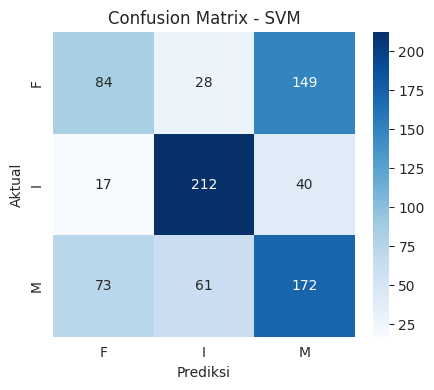


Random Forest
              precision    recall  f1-score   support

           F       0.46      0.36      0.41       261
           I       0.71      0.77      0.74       269
           M       0.49      0.54      0.52       306

    accuracy                           0.56       836
   macro avg       0.55      0.56      0.55       836
weighted avg       0.55      0.56      0.55       836



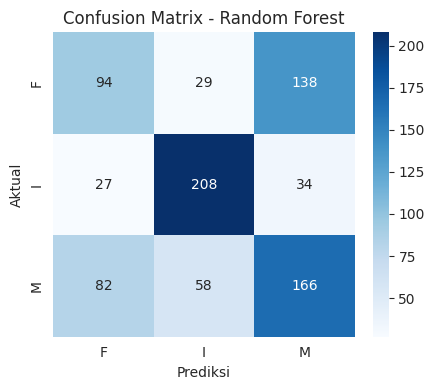

In [ ]:
results = {}
for name, search in [("SVM", svm_search), ("Random Forest", rf_search)]:
    y_pred = search.best_estimator_.predict(X_test)
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        # macro = rata-rata sederhana antar kelas
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "CV accuracy (train)": search.best_score_,
    }
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Prediksi"); plt.ylabel("Aktual")
    plt.tight_layout()
    plt.savefig(f"cm_{name.replace(' ', '_').lower()}.png", dpi=150)
    plt.show()

###**4. Perbandingan**


PERBANDINGAN SVM & RF
               Accuracy  Precision (macro)  Recall (macro)  \
SVM              0.5598             0.5545          0.5573   
Random Forest    0.5598             0.5531          0.5586   

               CV accuracy (train)  
SVM                         0.5630  
Random Forest               0.5591  


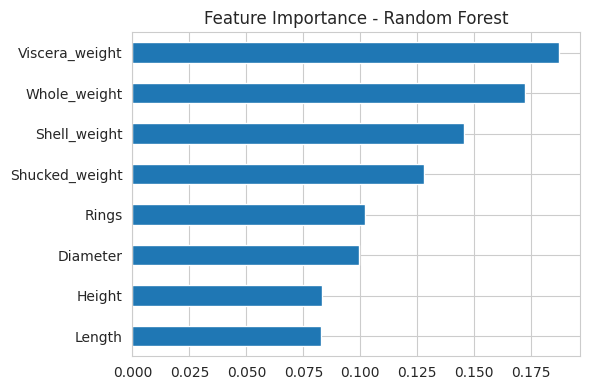

In [ ]:
comparison = pd.DataFrame(results).T.round(4)
print("\nPERBANDINGAN SVM & RF")
print(comparison)

rf_best = rf_search.best_estimator_.named_steps["clf"]
imp = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(6, 4), title="Feature Importance - Random Forest")
plt.tight_layout()
plt.savefig("rf_feature_importance.png", dpi=150)
plt.show()

Dari confusion matrix di atas, dapat disimpulkan bahwa:
* Akurasi kedua model hampir mirip.
* Kelas I (Infant) paling mudah ditebak karena ukurannya yang lebih kecil.
* Kelas M (Male) dan F (Female) memiliki ukuran yang mirip, karena bentuk tubuh jantan dan betine dewasa hampir sama.

**Model SVM**
* Kelebihan: Baik untuk karakteristik numerik yang sudah di scale, batas keputusan (RBF) bisa melengkung, dan relatif tahan overfitting jika c dan gamma disesuaikan (tuning).
* Kekurangan: sangat bergantung pada scaling dan tuning, lebih lambat kalau datanya besar (dapat dilihat 4.177 baris masih aman), dan sulit diinterpretasi.

**Random Forest**
* Kelebihan: tidak membutuhkan scaling, tahan terhadap outlier, menangkap hubungan non-linear, dan ada *feature importance* yang nyaman dipakai untuk pembahasan.
* Kekurangan: kalau tidak dibatasi (max_depth dan min_samples_leaf) mudah overfitting dan hasilnya kurang baik di batas antar kelas dibandingkan dengan SVM.

Accuracy f1-score pada SVM dan Random Forest memiliki angka yang sama, yaitu 0,56. Sedangkan CV accuracy di train, SVM menghasilkan angka yang lebih tinggi, yaitu 0,5630 dan Random Forest menghasilkan angka 0,5591. Perbedaan yang sangat tipis ini menunjukkan performanya setara satu model dengan model lainnya.

###**Part 2: Regression**
Task: Build a model to predict the number of rings in the abalone, which is a proxy of age.
* **Algorithms**: Implement at least two regression models (e.g., Simple Linear Regression, Multiple Linear Regression, etc).
* **Requirements**:
  * Draw the scatter plot and the regression from the models.
  * Predict the number of rings in the abalone.
  * Evaluate performance using Mean Squared Error (MSE).
  * **Comparison**: Compare the performance of the two regression models used. Which model performed better? Discuss the strengths and weaknesses of each algorithm regarding this specific dataset.  

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_style("whitegrid")

In [ ]:
from ucimlrepo import fetch_ucirepo
abalone = fetch_ucirepo(id=1)
df = pd.concat([abalone.data.features, abalone.data.targets], axis=1)

df = df[df["Height"] > 0].reset_index(drop=True)
print("Jumlah data setelah cleaning:", len(df))

num_cols = ["Length", "Diameter", "Height", "Whole_weight",
            "Shucked_weight", "Viscera_weight", "Shell_weight"]

Jumlah data setelah cleaning: 4175


Korelasi dengan Rings:
 Shell_weight      0.628
Diameter          0.574
Height            0.558
Length            0.556
Whole_weight      0.540
Viscera_weight    0.504
Shucked_weight    0.421
dtype: float64

Fitur untuk Simple Linear Regression: Shell_weight


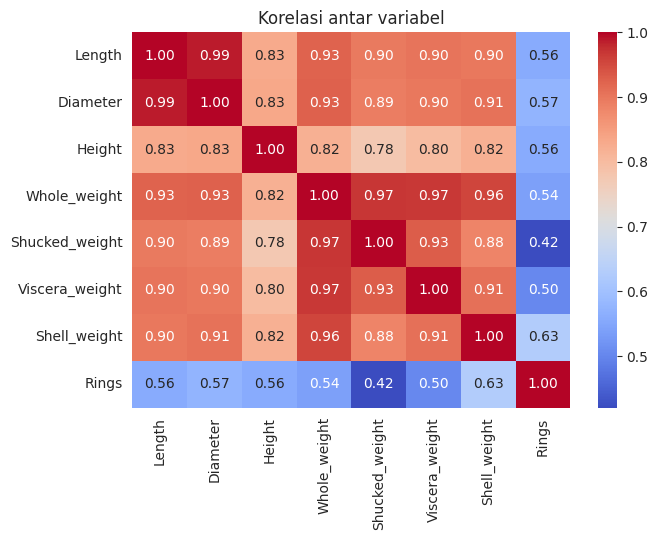

In [ ]:
# Korelasi tiap fitur dengan Rings, memilih 1 fitur terbaik untuk Simple Linear Regression
corr = df[num_cols].corrwith(df["Rings"]).sort_values(ascending=False)
print("Korelasi dengan Rings:\n", corr.round(3))
best_feat = corr.abs().idxmax()
print(f"\nFitur untuk Simple Linear Regression: {best_feat}")

plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols + ["Rings"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi antar variabel")
plt.tight_layout(); plt.savefig("reg_correlation.png", dpi=150); plt.show()

train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
y_train, y_test = train_df["Rings"], test_df["Rings"]

# Model 1: Simple Linear Regression (1 fitur)
m1 = LinearRegression().fit(train_df[[best_feat]], y_train)
p1_tr, p1_te = m1.predict(train_df[[best_feat]]), m1.predict(test_df[[best_feat]])

Dari korelasi heatmap di atas, dapat disimpulkan bahwa:
* Semua fitur (length, diameter, height, Whole_weight, Shucked_weight, Viscera_weight, & Shell_Weight) saling berkorelasi sangat tinggi, dengan nilai sekitar 0.8 sampai 0.99. Contohnya, Length dan Diameter 0.99 dimana abalone yang berukuran panjang pasti diameter dan beratnya juga besar.
* Korelasi antar variabel dengan Rings bersifat sedang, yaitu 0.42 sampai 0.63. Nilai tertinggi yaitu korelasi antara rings dengan shell_weight dimana cangkang semakin yebal dengan bertambahnya umur sehingga dipilih untuk Simple LR.

In [ ]:
# Model 2: Multiple Linear Regression (semua fitur + Sex one-hot)
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["Sex"]),
    ("num", StandardScaler(), num_cols),
])
feat_cols = ["Sex"] + num_cols
m2 = Pipeline([("prep", prep), ("reg", LinearRegression())]).fit(train_df[feat_cols], y_train)
p2_tr, p2_te = m2.predict(train_df[feat_cols]), m2.predict(test_df[feat_cols])

In [ ]:
# Model 3 (pembanding): Polynomial derajat 2, 1 fitur
m3 = Pipeline([("poly", PolynomialFeatures(degree=2, include_bias=False)),
               ("reg", LinearRegression())]).fit(train_df[[best_feat]], y_train)
p3_tr, p3_te = m3.predict(train_df[[best_feat]]), m3.predict(test_df[[best_feat]])

res = pd.DataFrame({
    "MSE train": [mean_squared_error(y_train, p) for p in (p1_tr, p2_tr, p3_tr)],
    "MSE test":  [mean_squared_error(y_test, p) for p in (p1_te, p2_te, p3_te)],
    "R2 test":   [r2_score(y_test, p) for p in (p1_te, p2_te, p3_te)],
}, index=[f"Simple LR ({best_feat})", "Multiple LR (semua fitur)",
          f"Polynomial deg-2 ({best_feat})"]).round(3)
print("\nHASIL REGRESI")
print(res)


HASIL REGRESI
                                 MSE train  MSE test  R2 test
Simple LR (Shell_weight)             6.160     6.841    0.401
Multiple LR (semua fitur)            4.784     4.911    0.570
Polynomial deg-2 (Shell_weight)      5.991     6.759    0.408



Koefisien Multiple LR (fitur sudah di-scale):
num__Shucked_weight   -4.133
num__Viscera_weight   -0.917
cat__Sex_I            -0.536
num__Length           -0.172
cat__Sex_F             0.217
cat__Sex_M             0.319
num__Height            0.442
num__Diameter          1.231
num__Shell_weight      1.282
num__Whole_weight      3.850
dtype: float64


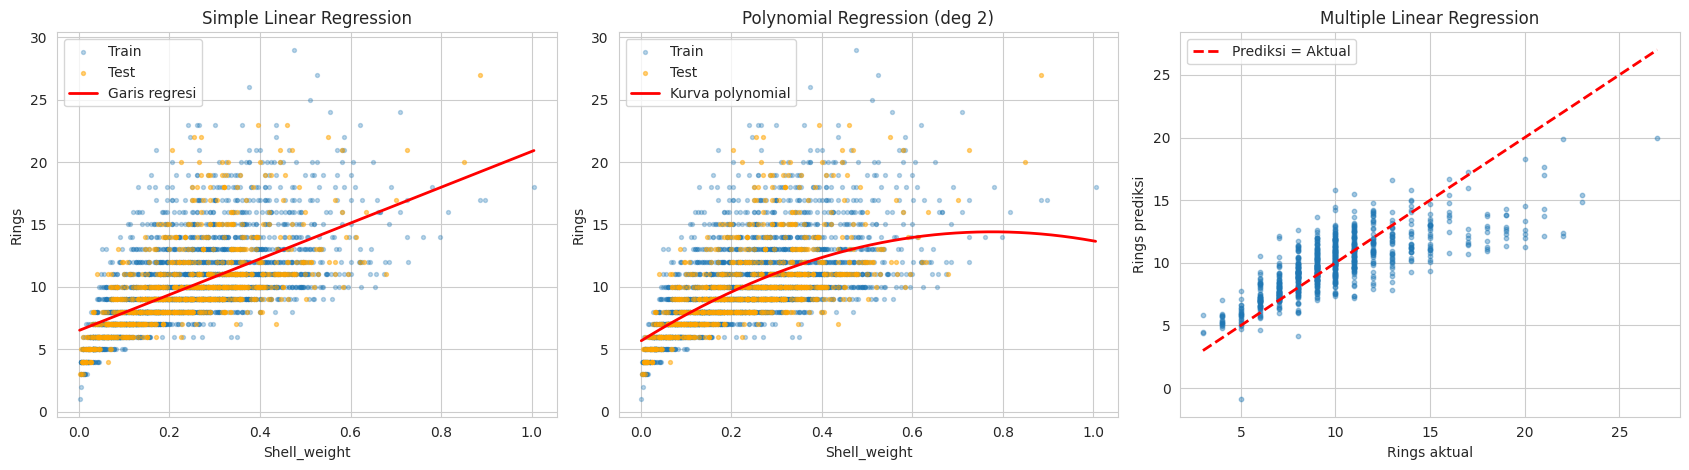

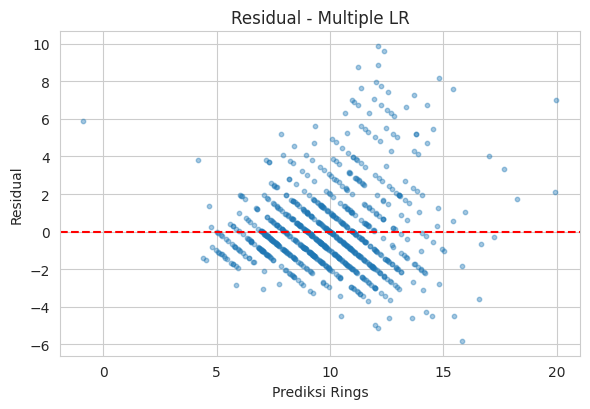


Contoh prediksi Rings:
      Sex  Rings_aktual  Pred_Multiple_LR
2330   M            15             13.31
2411   M             7              7.90
2195   I            11              7.32
2381   I            11              9.66
3571   F             9             10.32


In [ ]:
# Koefisien Multiple LR
names = m2.named_steps["prep"].get_feature_names_out()
print("\nKoefisien Multiple LR (fitur sudah di-scale):")
print(pd.Series(m2.named_steps["reg"].coef_, index=names).round(3).sort_values())

# Plot: scatter + garis regresi
xs = np.linspace(df[best_feat].min(), df[best_feat].max(), 300).reshape(-1, 1)
xs_df = pd.DataFrame(xs, columns=[best_feat])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a in ax[:1]:
    a.scatter(train_df[best_feat], y_train, s=8, alpha=0.3, label="Train")
    a.scatter(test_df[best_feat], y_test, s=8, alpha=0.5, color="orange", label="Test")
    a.plot(xs, m1.predict(xs_df), "r-", lw=2, label="Garis regresi")
    a.set(xlabel=best_feat, ylabel="Rings", title="Simple Linear Regression")
    a.legend()
ax[1].scatter(train_df[best_feat], y_train, s=8, alpha=0.3, label="Train")
ax[1].scatter(test_df[best_feat], y_test, s=8, alpha=0.5, color="orange", label="Test")
ax[1].plot(xs, m3.predict(xs_df), "r-", lw=2, label="Kurva polynomial")
ax[1].set(xlabel=best_feat, ylabel="Rings", title="Polynomial Regression (deg 2)")
ax[1].legend()
# Multiple LR memiliki >1 fitur, jadi digambar sebagai Aktual vs Prediksi
ax[2].scatter(y_test, p2_te, s=10, alpha=0.4)
lim = [y_test.min(), y_test.max()]
ax[2].plot(lim, lim, "r--", lw=2, label="Prediksi = Aktual")
ax[2].set(xlabel="Rings aktual", ylabel="Rings prediksi", title="Multiple Linear Regression")
ax[2].legend()
plt.tight_layout(); plt.savefig("reg_scatter_lines.png", dpi=150); plt.show()

# Plot residual Multiple LR
plt.figure(figsize=(6, 4.2))
plt.scatter(p2_te, y_test - p2_te, s=10, alpha=0.4)
plt.axhline(0, color="r", ls="--")
plt.xlabel("Prediksi Rings"); plt.ylabel("Residual"); plt.title("Residual - Multiple LR")
plt.tight_layout(); plt.savefig("reg_residual.png", dpi=150); plt.show()

# Contoh prediksi untuk beberapa abalone di test set
contoh = test_df[["Sex"] + num_cols].head(5).copy()
contoh["Rings_aktual"] = y_test.head(5).values
contoh["Pred_Multiple_LR"] = p2_te[:5].round(2)
print("\nContoh prediksi Rings:\n", contoh[["Sex", "Rings_aktual", "Pred_Multiple_LR"]])

Dari scatter plot di atas, dapat disimpulkan bahwa:
* Model dengan performa lebih baik adalah Multiple LR dengan MSE_test nya 4.911.
* Simple LR
  * Kelebihan: mudah dimenegerti dan digambarkan
  * Kekurangan: Hanya memiliki satu fitur dan nilai MSE nya paling tinggi.
* Multiple LR
  * Kelebihan: menggunakan semua informasi dan paling akurat.
  * Kekurangan: koefisien sulit diinterpretasikan karena korelasinya yang sempurna antar variabel bebas atau independen.mengabaikan umur abalone yang tua, dan dapat memprediksi nilai negatif.
* Polynomial
  * Kelebihan: dapat memunculkan kelengkungan
  * Kekurangan: perbaikannya sangat kecil dan bentuk kurva di ujung kanan tidak bisa dipercaya.

###**Part 3: Clustering**
Task: Identify natural groupings within the dataset based on physical characteristics, ignoring the target variables.
* **Algorithms**: Implement **K-means Clustering, Spectral Clustering,** and **Hierarchical Clustering**.
* **Requirements**:
  * Determine the optimal number of clusters.
  * Visualize the clusters.
  * **Comparison**: Compare the groupings produced by the three algorithms. Do any of the resulting clusters align with the true sex or age categories of the abalone? Discuss why one algorithm might be more appropriate than the others for this data structure.  

In [ ]:
X_clu = StandardScaler().fit_transform(df[num_cols])

# Kategori umur dari Rings
df["Age_group"] = pd.cut(df["Rings"], bins=[0, 8, 10, 40],
                         labels=["Young (<=8)", "Adult (9-10)", "Old (>=11)"])

def make_model(name, k):
    if name == "K-means":
        return KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    if name == "Spectral":
        return SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                  n_neighbors=15, assign_labels="kmeans",
                                  random_state=RANDOM_STATE)
    return AgglomerativeClustering(n_clusters=k, linkage="ward")

algos = ["K-means", "Spectral", "Hierarchical"]

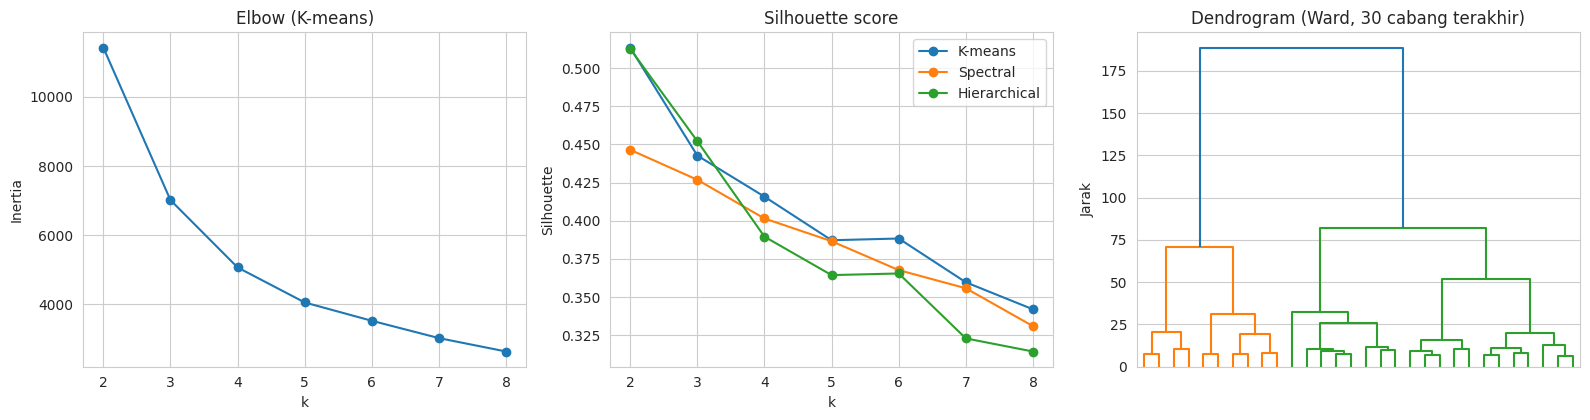

Silhouette per k:
    K-means  Spectral  Hierarchical
2    0.513     0.446         0.513
3    0.443     0.427         0.452
4    0.416     0.401         0.390
5    0.387     0.387         0.364
6    0.388     0.368         0.365
7    0.360     0.356         0.323
8    0.342     0.331         0.314

k terbaik menurut silhouette K-means: 2


In [ ]:
ks = list(range(2, 9))
sil = {a: [] for a in algos}
inertia = []
for k in ks:
    for a in algos:
        labels = make_model(a, k).fit_predict(X_clu)
        sil[a].append(silhouette_score(X_clu, labels))
    inertia.append(KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_clu).inertia_)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow (K-means)", xlabel="k", ylabel="Inertia")
for a in algos:
    ax[1].plot(ks, sil[a], "o-", label=a)
ax[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette"); ax[1].legend()
Z_link = linkage(X_clu, method="ward")
dendrogram(Z_link, truncate_mode="lastp", p=30, ax=ax[2], no_labels=True)
ax[2].set(title="Dendrogram (Ward, 30 cabang terakhir)", ylabel="Jarak")
plt.tight_layout(); plt.savefig("clu_k_selection.png", dpi=150); plt.show()

sil_df = pd.DataFrame(sil, index=ks).round(3)
print("Silhouette per k:\n", sil_df)
K_OPT = int(sil_df["K-means"].idxmax())
print(f"\nk terbaik menurut silhouette K-means: {K_OPT}")

**Jumlah cluster optimal:**
* Elbow (k-means): karena plot grafiknya menurun signifikan dan mulai melandai di sekitar nilai kk = 4 sampai 5, maka tidak ada garis tegas dan struktur kelompok yang tajam.
* Silhouette score: Plot grafik tertinggi berada di nilai K = 2 untuk ketiganya, dimana K-means dan Hierarchical berada di atas 0.5 dan spectral berada di angka mendekati 0.450. Jika skor silhouette semakin tinggi, maka cluster semakin rapi dan terpisah.
* Dendogram (Ward, 30 cabang terakhir): di atas jarak 175, terdapat dua kelompok besar yang paling jauh jaraknya sehingga pemotongan terbaik menghasilkan 2 cluster. Potongan berikutnya, sekitar jarak 80, menghasilkan 3 cluster.

Dapat disimpulkan bahwa nilai K = 2 dari Silhouette score merupakan k terbaik, disusul k + 3 dapat dianalisis lebih lanjut karena angka nya lumayan baik, yaitu 0.43 - 0.45. Selain itu, cocok dengan 3 kategori sex dan 3 kelompok umur.

Varians dijelaskan PC1 & PC2: 94.8%

--- K-means, k=2 ---
Ukuran cluster: {0: np.int64(1937), 1: np.int64(2238)}
Cluster vs Sex (proporsi per cluster):
 Sex       F     I     M
row_0                  
0      0.17  0.59  0.24
1      0.44  0.09  0.47
Cluster vs Kelompok umur (proporsi per cluster):
 Age_group  Young (<=8)  Adult (9-10)  Old (>=11)
row_0                                           
0                 0.61          0.22        0.16
1                 0.10          0.40        0.50
Rata-rata Rings per cluster:
 {0: 8.32, 1: 11.33}

--- Spectral, k=2 ---
Ukuran cluster: {0: np.int64(3324), 1: np.int64(851)}
Cluster vs Sex (proporsi per cluster):
 Sex       F     I     M
row_0                  
0      0.38  0.21  0.41
1      0.07  0.76  0.18
Cluster vs Kelompok umur (proporsi per cluster):
 Age_group  Young (<=8)  Adult (9-10)  Old (>=11)
row_0                                           
0                 0.21          0.37        0.42
1                 0.83          0.12        0

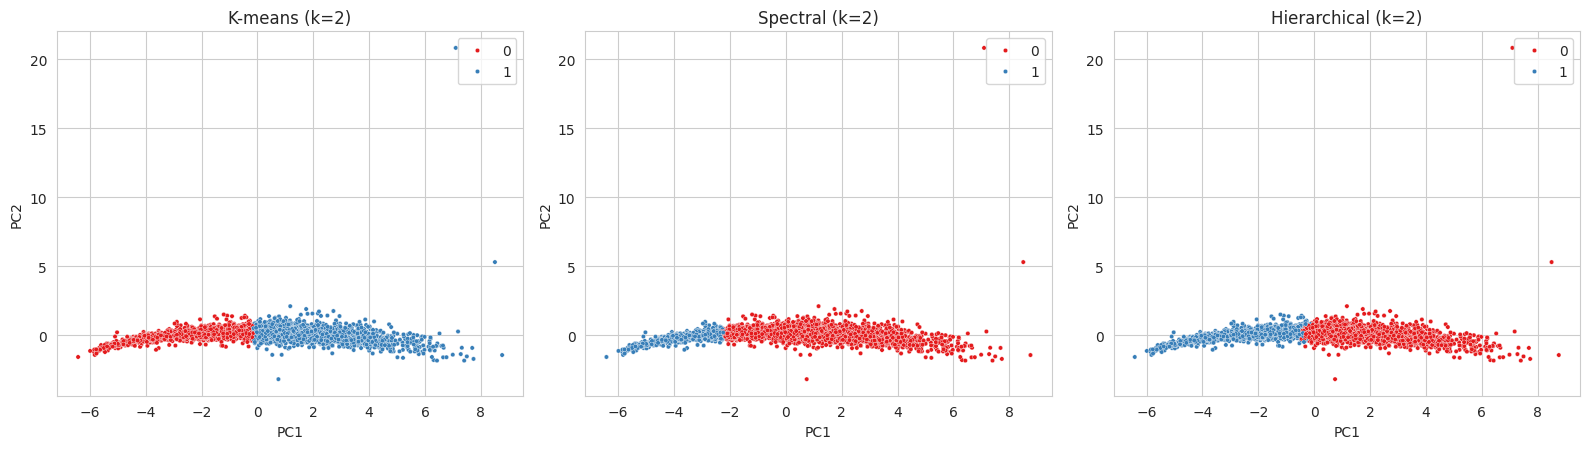


--- K-means, k=3 ---
Ukuran cluster: {0: np.int64(1253), 1: np.int64(1759), 2: np.int64(1163)}
Cluster vs Sex (proporsi per cluster):
 Sex       F     I     M
row_0                  
0      0.47  0.03  0.50
1      0.33  0.27  0.39
2      0.11  0.71  0.19
Cluster vs Kelompok umur (proporsi per cluster):
 Age_group  Young (<=8)  Adult (9-10)  Old (>=11)
row_0                                           
0                 0.04          0.38        0.58
1                 0.26          0.38        0.36
2                 0.77          0.15        0.08
Rata-rata Rings per cluster:
 {0: 11.68, 1: 10.42, 2: 7.33}

--- Spectral, k=3 ---
Ukuran cluster: {0: np.int64(1576), 1: np.int64(2298), 2: np.int64(301)}
Cluster vs Sex (proporsi per cluster):
 Sex       F     I     M
row_0                  
0      0.20  0.55  0.25
1      0.43  0.10  0.47
2      0.02  0.82  0.16
Cluster vs Kelompok umur (proporsi per cluster):
 Age_group  Young (<=8)  Adult (9-10)  Old (>=11)
row_0                             

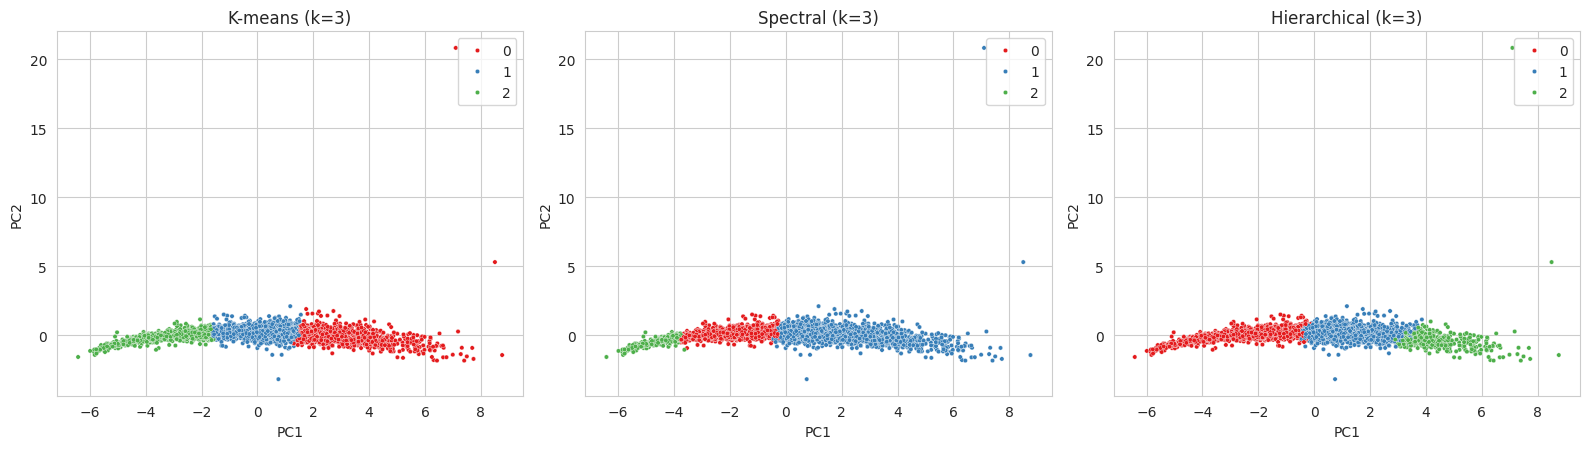

In [ ]:
K_LIST = sorted({K_OPT, 3})

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_clu)
print(f"Varians dijelaskan PC1 & PC2: {pca.explained_variance_ratio_.sum():.1%}")

summary = []
for k in K_LIST:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    for i, a in enumerate(algos):
        labels = make_model(a, k).fit_predict(X_clu)
        df[f"{a}_k{k}"] = labels
        sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=labels, palette="Set1",
                        s=10, ax=ax[i], legend="full")
        ax[i].set(title=f"{a} (k={k})", xlabel="PC1", ylabel="PC2")

        summary.append({
            "k": k, "Algoritma": a,
            "Silhouette": silhouette_score(X_clu, labels),
            "ARI vs Sex": adjusted_rand_score(df["Sex"], labels),
            "NMI vs Sex": normalized_mutual_info_score(df["Sex"], labels),
            "ARI vs Umur": adjusted_rand_score(df["Age_group"], labels),
            "NMI vs Umur": normalized_mutual_info_score(df["Age_group"], labels),
        })
        print(f"\n--- {a}, k={k} ---")
        print("Ukuran cluster:", dict(pd.Series(labels).value_counts().sort_index()))
        print("Cluster vs Sex (proporsi per cluster):\n",
              pd.crosstab(labels, df["Sex"], normalize="index").round(2))
        print("Cluster vs Kelompok umur (proporsi per cluster):\n",
              pd.crosstab(labels, df["Age_group"], normalize="index").round(2))
        print("Rata-rata Rings per cluster:\n",
              df.groupby(labels)["Rings"].mean().round(2).to_dict())
    plt.tight_layout(); plt.savefig(f"clu_pca_k{k}.png", dpi=150); plt.show()

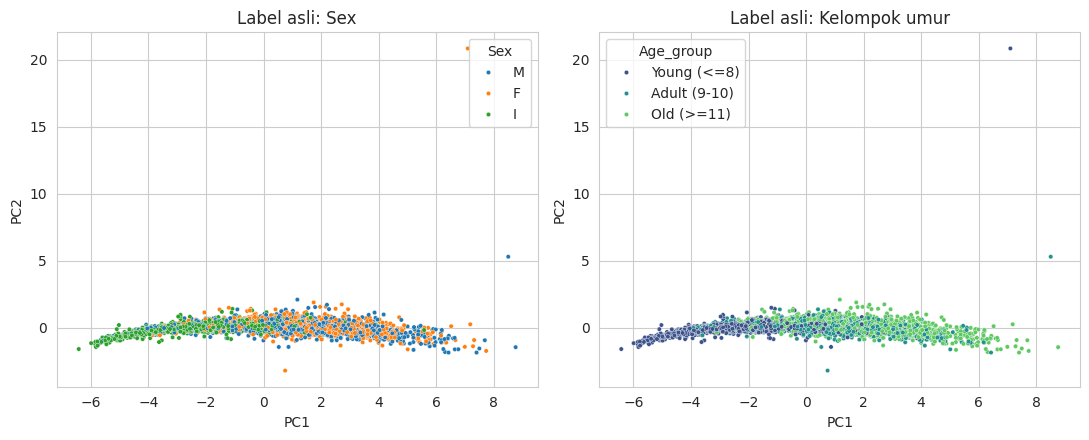

RINGKASAN PERBANDINGAN CLUSTERING
 k    Algoritma  Silhouette  ARI vs Sex  NMI vs Sex  ARI vs Umur  NMI vs Umur
 2      K-means       0.513       0.184       0.170        0.202        0.181
 2     Spectral       0.446       0.090       0.136        0.111        0.179
 2 Hierarchical       0.513       0.181       0.165        0.206        0.185
 3      K-means       0.443       0.132       0.160        0.164        0.187
 3     Spectral       0.427       0.156       0.166        0.166        0.193
 3 Hierarchical       0.452       0.153       0.152        0.179        0.177


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["Sex"], s=10, ax=ax[0])
ax[0].set(title="Label asli: Sex", xlabel="PC1", ylabel="PC2")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["Age_group"], palette="viridis", s=10, ax=ax[1])
ax[1].set(title="Label asli: Kelompok umur", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.savefig("clu_true_labels.png", dpi=150); plt.show()

print("RINGKASAN PERBANDINGAN CLUSTERING")
print(pd.DataFrame(summary).round(3).to_string(index=False))

Dari perbandingan di atas, dapat disimpulkan bahwa:
* Algoritma yang paling cocok adalah K-means atau Hierarchical.
* Bentuk datanya seperti satu awan memanjang.
* K-menas lebih unggul di kecepatan dan kesederhanaan. Sedangkan Hierarchical unggul di kemampuan memperlihatkan hierarki lewat dendogram.
* Cluster menggambarkan langkah pertumbuhan seperti "kecil vs muda" dan "besar vs tua".
* Cluster hanya sebagian cocok atau lemah dengan Sex karena hanya memisahkan variabel infant dari dewasa (Male & Female) dan variabel Male & Female tidak terpisah.
* Cluster lebih cocok dengan kategori umur walaupun di tingkat sedang. Dikarenakan ukuran memang berhubungan dengan umur karena laju tumbuh tiap abalone berbeda-beda.